# 08 - Error analysis

The tuned models all reach about 0.68 in CV (experiment 04): the limit is now the information in the
features, not the model. This notebook looks at **where the model is wrong**, to decide which features to
build next. Everything is on the **train set only**, with out-of-fold (OOF) predictions: each battle is
predicted by a model that did not see it.

Questions:
1. How confident is the model, and how are the errors spread over the confidence levels?
2. In which kinds of battles is it worse (close HP, unseen P2 Pokémon, sleep, boosts, ...)?
3. What do the confident errors have in common?
4. Is there signal left in the residuals, in existing features, species or **candidate new features**?
5. Would more data or a more complex model help (learning curve)?

Model: the tuned LightGBM of experiment 04 (the fastest of the best models), all 155 numeric features.
Inputs: `data/processed/` from notebooks 02 and 03.

## 0. Setup

In [13]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, learning_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models import get_model_specs, with_params
from src.preprocessing import N_TURNS, STATS
from src.validation import REPEAT_SEEDS, SEED

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
PROC = ROOT / "data" / "processed"
N_JOBS = -1

features = pd.read_pickle(PROC / "features_train.pkl")
with open(PROC / "feature_groups.json") as f:
    groups = json.load(f)
y = features.pop("player_won")
CAT = groups["species_cat"]
NUM = [c for c in features.columns if c not in CAT]
X = features[NUM]

timeline = pd.read_pickle(PROC / "timeline_train.pkl")
states = pd.read_pickle(PROC / "states_train.pkl")
team = pd.read_pickle(PROC / "team_train.pkl")
species = pd.read_pickle(PROC / "species_table.pkl")
print(f"battles: {len(X):,} | features: {X.shape[1]}")

battles: 10,000 | features: 155


## 1. Out-of-fold predictions

Stratified 5-fold CV repeated with seeds 42, 7 and 123: every battle gets three OOF probabilities, which are
averaged (this is a small ensemble, so the averaged accuracy can be slightly above the single-seed ones).

In [14]:
# Tuned in experiment 04 (notebooks/04_models.ipynb)
LGBM_PARAMS = {
    "model__colsample_bytree": 0.6286197472598067, "model__learning_rate": 0.006552992991573526,
    "model__min_child_samples": 106, "model__n_estimators": 1424, "model__num_leaves": 12,
    "model__reg_alpha": 0.6070874110546393, "model__reg_lambda": 2.7129089558470034,
    "model__subsample": 0.6629794526009424,
}
model = with_params(get_model_specs()["lightgbm"], LGBM_PARAMS)

t0 = time.time()
oof_runs = []
for s in REPEAT_SEEDS:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
    p_s = cross_val_predict(model, X, y, cv=cv, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    oof_runs.append(p_s)
    print(f"seed {s:3d}: OOF accuracy {((p_s >= 0.5) == y).mean():.4f}")
p = np.mean(oof_runs, axis=0)
print(f"averaged over seeds: {((p >= 0.5) == y).mean():.4f}  ({time.time() - t0:.0f}s)")

df = pd.DataFrame({"y": y, "p": p}, index=X.index)
df["pred"] = (df["p"] >= 0.5).astype(int)
df["correct"] = df["pred"] == df["y"]
df["conf"] = (df["p"] - 0.5).abs() * 2        # 0 = coin flip, 1 = certain
df["residual"] = df["y"] - df["p"]            # > 0: P1 won more often than predicted
df.to_pickle(PROC / "oof_lgbm.pkl")

seed  42: OOF accuracy 0.6798
seed   7: OOF accuracy 0.6784
seed 123: OOF accuracy 0.6755
averaged over seeds: 0.6795  (14s)


## 2. Confidence and calibration

If the model is calibrated, a battle predicted at 0.7 is won by P1 70% of the times, and the accuracy in
a confidence band is the best any model with the same information could do there. The share of battles
with low confidence tells us how much room there is: errors on confident predictions point to missing
information, errors near 0.5 may be close to irreducible.

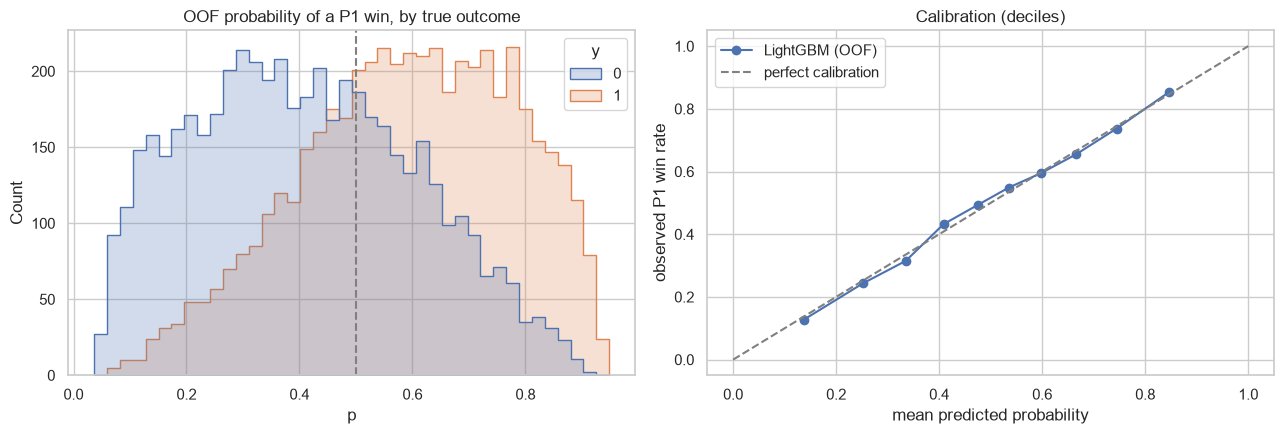

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="p", hue="y", bins=40, element="step", stat="count", ax=axes[0])
axes[0].axvline(0.5, c="grey", ls="--")
axes[0].set_title("OOF probability of a P1 win, by true outcome")

frac_pos, mean_pred = calibration_curve(df["y"], df["p"], n_bins=10, strategy="quantile")
axes[1].plot(mean_pred, frac_pos, "o-", label="LightGBM (OOF)")
axes[1].plot([0, 1], [0, 1], c="grey", ls="--", label="perfect calibration")
axes[1].set_xlabel("mean predicted probability")
axes[1].set_ylabel("observed P1 win rate")
axes[1].set_title("Calibration (deciles)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [16]:
bands = pd.cut(df["conf"], [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0], include_lowest=True)
by_conf = df.groupby(bands, observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                               errors=("correct", lambda s: (~s).sum()))
by_conf["share_of_battles"] = by_conf["n"] / len(df)
by_conf["share_of_errors"] = by_conf["errors"] / (~df["correct"]).sum()
by_conf.round(3)

,n,accuracy,errors,share_of_battles,share_of_errors
conf,,,,,
"(-0.001, 0.1]",1624,0.532,760,0.162,0.237
"(0.1, 0.2]",1540,0.568,665,0.154,0.207
"(0.2, 0.3]",1451,0.616,557,0.145,0.174
"(0.3, 0.4]",1303,0.676,422,0.130,0.132
"(0.4, 0.5]",1192,0.736,315,0.119,0.098
"(0.5, 0.6]",1019,0.766,238,0.102,0.074
"(0.6, 0.8]",1533,0.850,230,0.153,0.072
"(0.8, 1.0]",338,0.947,18,0.034,0.006


## 3. Accuracy by kind of battle

For each slice: size, accuracy, real P1 win rate, mean predicted probability and mean confidence.
A slice with low accuracy **and** high confidence is where information is missing; a slice with low accuracy
and low confidence is simply hard (close battles).

In [17]:
def slice_report(masks):
    rows = []
    for name, m in masks.items():
        d = df[m]
        if len(d) == 0:
            continue
        rows.append({"slice": name, "n": len(d), "share": len(d) / len(df), "accuracy": d["correct"].mean(),
                     "p1_win_rate": d["y"].mean(), "mean_p": d["p"].mean(), "mean_conf": d["conf"].mean()})
    return pd.DataFrame(rows).set_index("slice")

boost_t30 = [c for c in X.columns if c.startswith(("p1_boost_", "p2_boost_")) and c.endswith("_t30")]
masks = {
    "all battles": pd.Series(True, index=df.index),
    "no KO recorded at all": (X["p1_ko"] + X["p2_ko"]) == 0,
    "P1 lost >= 3 (recorded)": X["p1_ko"] >= 3,
    "P2 lost_est >= 3": X["p2_lost_est"] >= 3,
    "lost_est equal on both sides": X["diff_lost_est"] == 0,
    "P2 has >= 3 unseen Pokémon": X["p2_seen"] <= 3,
    "P2 has 0 unseen Pokémon": X["p2_seen"] >= 6,
    "P2 vanished with low HP": X["p2_vanished_low50"] > 0,
    "|diff_hp_total| < 0.5": X["diff_hp_total"].abs() < 0.5,
    "|diff_hp_total| >= 1.5": X["diff_hp_total"].abs() >= 1.5,
    "any boost on the field at turn 30": (X[boost_t30] != 0).any(axis=1),
    "P1 boosted at turn 30": (X[[c for c in boost_t30 if c.startswith("p1_")]] > 0).any(axis=1),
    "P2 boosted at turn 30": (X[[c for c in boost_t30 if c.startswith("p2_")]] > 0).any(axis=1),
    "sleep involved (any side)": (X["p1_turns_slp"] + X["p2_turns_slp"]) > 0,
    ">= 2 P1 Pokémon statused": X["p1_statused"] >= 2,
    ">= 2 P2 Pokémon statused": X["p2_statused"] >= 2,
    "Explosion / Self-Destruct used": (X["p1_n_explosion_moves"] + X["p2_n_explosion_moves"]) > 0,
    "hazards used": (X["p1_n_hazard_moves"] + X["p2_n_hazard_moves"]) > 0,
    "Substitute used": (X["p1_turns_substitute"] + X["p2_turns_substitute"]) > 0,
    "under-levelled battle": X["p1_n_underlevel"] > 0,
    "P1 active faster at turn 30": X["m_active_p1_faster"] == 1,
    "P1 active slower at turn 30": X["m_active_p1_faster"] == 0,
}
slices = slice_report(masks)
slices.round(3)

,n,share,accuracy,p1_win_rate,mean_p,mean_conf
slice,,,,,,
all battles,10000,1.000,0.680,0.500,0.500,0.357
no KO recorded at all,2441,0.244,0.648,0.606,0.598,0.304
P1 lost >= 3 (recorded),2706,0.271,0.733,0.359,0.363,0.445
P2 lost_est >= 3,2649,0.265,0.714,0.592,0.592,0.421
lost_est equal on both sides,3069,0.307,0.620,0.556,0.558,0.245
P2 has >= 3 unseen Pokémon,249,0.025,0.719,0.373,0.359,0.443
P2 has 0 unseen Pokémon,5410,0.541,0.680,0.552,0.544,0.359
P2 vanished with low HP,6949,0.695,0.688,0.530,0.530,0.379
|diff_hp_total| < 0.5,3404,0.340,0.619,0.595,0.593,0.249


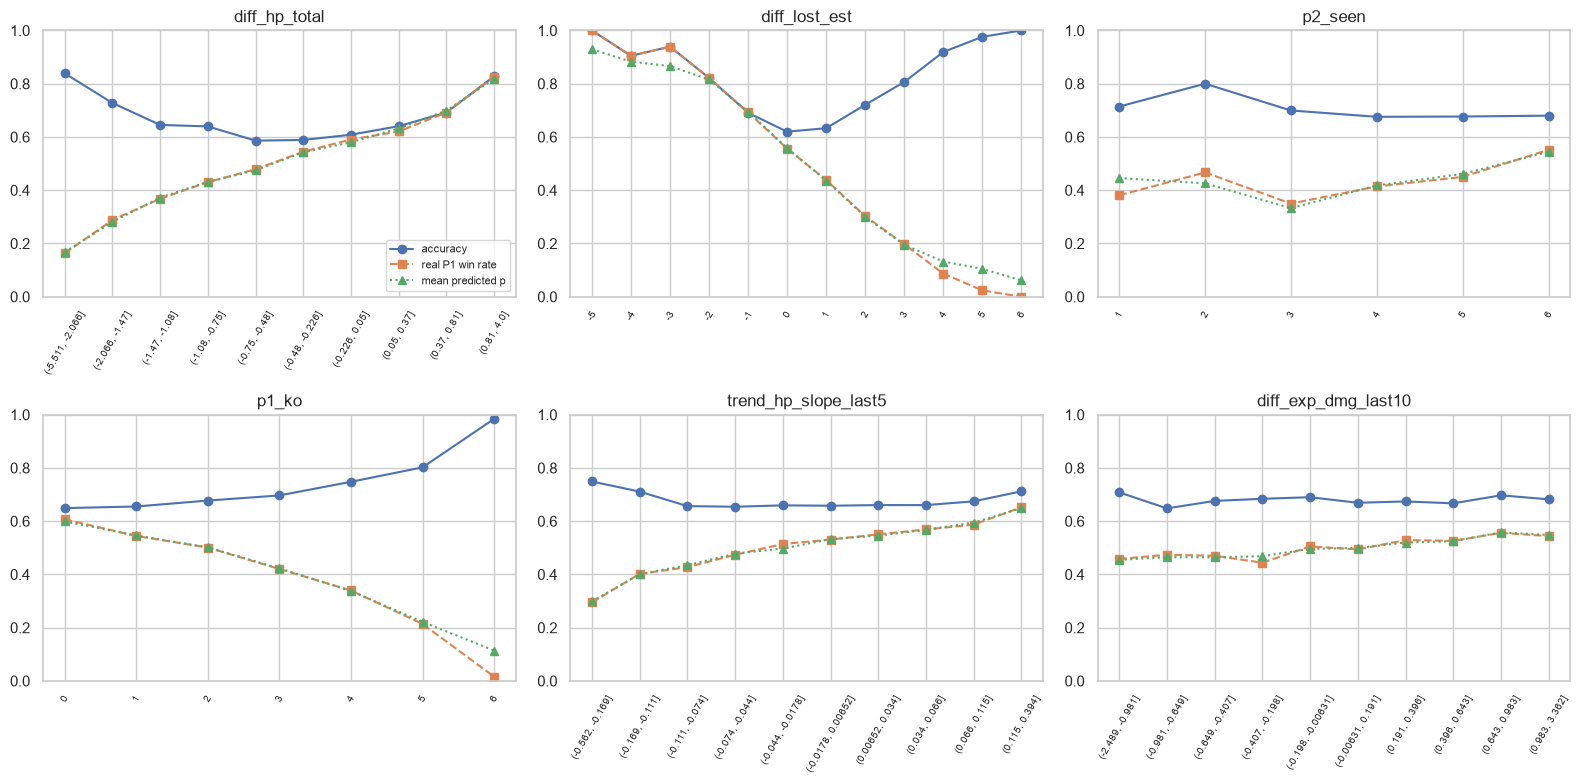

In [18]:
def by_bins(col, bins=10, ax=None):
    # Accuracy and real P1 win rate along one feature (quantile bins, or exact values if few)
    s = X[col]
    key = s if s.nunique() <= 12 else pd.qcut(s, bins, duplicates="drop")
    g = df.groupby(key, observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                           p1_win_rate=("y", "mean"), mean_p=("p", "mean"))
    labels = [str(i) for i in g.index]
    ax.plot(labels, g["accuracy"], "o-", label="accuracy")
    ax.plot(labels, g["p1_win_rate"], "s--", label="real P1 win rate")
    ax.plot(labels, g["mean_p"], "^:", label="mean predicted p")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=60, labelsize=7)
    ax.set_ylim(0, 1)
    return g

cols = ["diff_hp_total", "diff_lost_est", "p2_seen", "p1_ko", "trend_hp_slope_last5", "diff_exp_dmg_last10"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, ax in zip(cols, axes.ravel()):
    by_bins(col, ax=ax)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Confident errors

Battles where the model was confident (`conf ≥ 0.5`, i.e. p ≤ 0.25 or p ≥ 0.75) and wrong. They are compared
with the confident **correct** predictions **within the same predicted class**: among the battles predicted
as a P1 win, what distinguishes the ones P1 lost from the ones P1 won (and the same for predicted P2 wins).
Comparing inside one class keeps every feature with its own meaning, with no sign flipping.

The measure is the standardised mean difference, (mean in the errors - mean in the correct predictions) /
standard deviation over all battles.

confident predictions: 2,890 (28.9%) | wrong among them: 486 (16.8%)
predicted P1 win: 1,429 confident, 250 wrong
predicted P2 win: 1,461 confident, 236 wrong


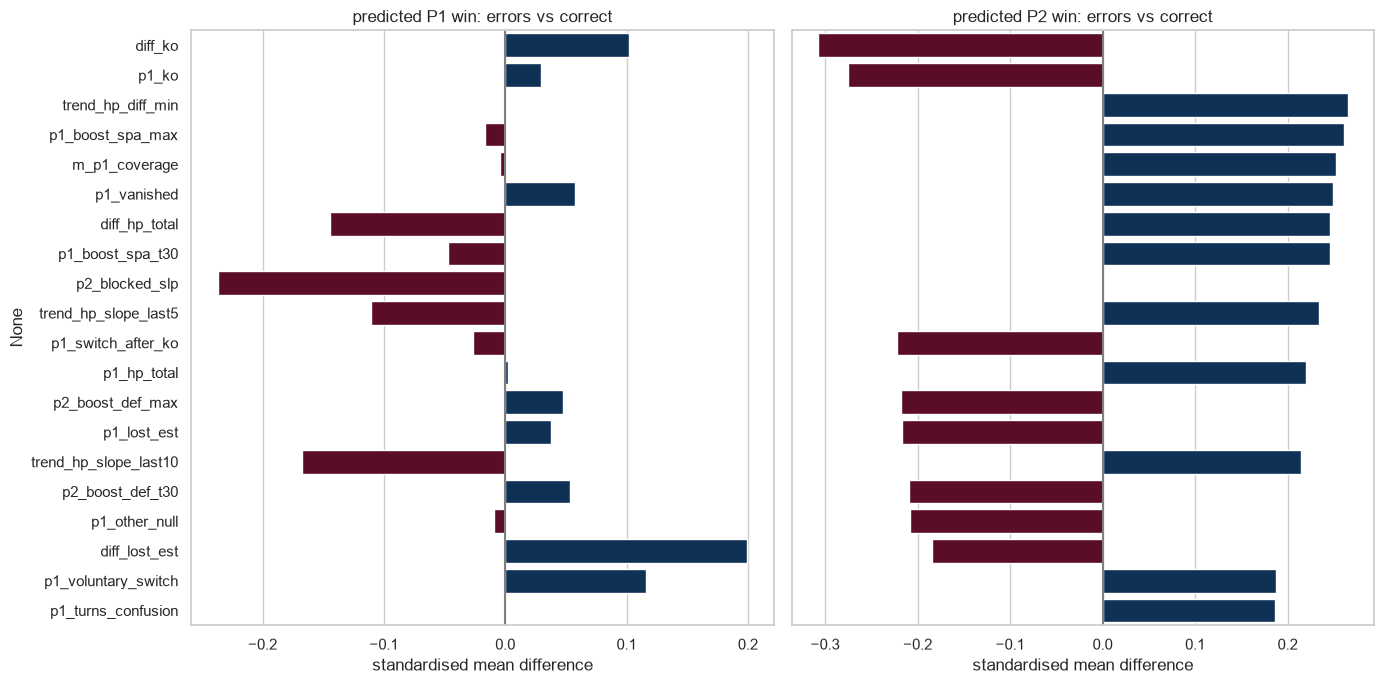

,predicted P1 win,predicted P2 win
diff_ko,0.102,-0.308
p1_ko,0.029,-0.276
trend_hp_diff_min,-0.002,0.265
p1_boost_spa_max,-0.017,0.261
m_p1_coverage,-0.004,0.252
p1_vanished,0.057,0.249
diff_hp_total,-0.144,0.246
p1_boost_spa_t30,-0.047,0.246
p2_blocked_slp,-0.237,-0.002
trend_hp_slope_last5,-0.111,0.234


In [19]:
confident = df["conf"] >= 0.5
print(f"confident predictions: {confident.sum():,} ({confident.mean():.1%}) | "
      f"wrong among them: {(confident & ~df['correct']).sum():,} "
      f"({(confident & ~df['correct']).sum() / confident.sum():.1%})")

std = X.std().replace(0, np.nan)
smd = {}
for pred, label in [(1, "predicted P1 win"), (0, "predicted P2 win")]:
    in_class = confident & (df["pred"] == pred)
    wrong, right = in_class & ~df["correct"], in_class & df["correct"]
    print(f"{label}: {in_class.sum():,} confident, {wrong.sum():,} wrong")
    smd[label] = ((X[wrong].mean() - X[right].mean()) / std).dropna()
smd = pd.DataFrame(smd)

# Features that separate errors from correct predictions the most, in either class
top = smd.abs().max(axis=1).sort_values(ascending=False).head(20).index
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, col in zip(axes, smd.columns):
    vals = smd.loc[top, col]
    sns.barplot(x=vals.values, y=top, hue=np.sign(vals.values), palette="RdBu", legend=False, ax=ax)
    ax.axvline(0, c="grey")
    ax.set_title(f"{col}: errors vs correct")
    ax.set_xlabel("standardised mean difference")
plt.tight_layout()
plt.show()
smd.loc[top].round(3)

How to read it: in the "predicted P1 win" panel, a negative `diff_hp_total` means that the battles P1 then
lost had a smaller HP advantage than the ones P1 won, which is expected. A feature that is far from 0 **in
both panels with opposite signs** (or in one panel only) and is not just a weaker version of the strongest
features would point to missing information.

The first version of this section flipped the sign of every feature according to the predicted winner. That
was wrong for single-side and static features (e.g. `p1_team_max_bst`, always positive): their difference
only reflected how many errors were predicted P1 vs P2 wins, not anything about the battles.

## 5. Is there signal left in the residuals?

The residual is `y - p`. If a quantity is correlated with it, the model is not fully using it: that is a
cheap first screening before building and cross-validating a new feature (a real test still needs CV).

### 5.1 Existing features

In [20]:
res_corr = X.corrwith(df["residual"], method="spearman").dropna()
res_corr.reindex(res_corr.abs().sort_values(ascending=False).index).head(15).round(4).to_frame("spearman r with residual")

,spearman r with residual
diff_hp_total,-0.0683
trend_hp_diff_min,-0.0602
trend_hp_diff_mean,-0.0575
trend_hp_diff_t25,-0.0569
diff_lost_est,0.0557
trend_hp_diff_t20,-0.0480
trend_hp_slope_last10,-0.0442
trend_hp_diff_max,-0.0420
p1_boost_spa_t30,0.0397
p1_hp_total,-0.0378


For boosting the values should be tiny (it already uses the features non-linearly); anything above ~0.03
in absolute value (|r| > 2/√n ≈ 0.02 is the rough noise level with 10,000 battles) deserves a look.

**Caveat (after the run).** The largest values (`diff_hp_total` and the HP trend, about -0.06) are not missing
information: the plots of section 3 show that the mean predicted probability matches the real win rate in
every bin of `diff_hp_total`. A Spearman correlation with a residual of a binary target is not zero even for a
calibrated model, because the residual takes two very different shapes for wins and losses. The calibration by
bins (section 3) is the reliable check; this table is only a rough screening.

### 5.2 Species

Mean residual per species of the P2 lead and of the active Pokémon at turn 30 (only species with at least
50 battles). `z` is the mean residual divided by its standard error: |z| > 3 means the model is
systematically wrong for that species.

In [21]:
rows = []
for col in CAT:
    g = df["residual"].groupby(features[col])
    stats = pd.DataFrame({"n": g.size(), "mean_residual": g.mean(), "std": g.std()})
    stats = stats[stats["n"] >= 50]
    stats["z"] = stats["mean_residual"] / (stats["std"] / np.sqrt(stats["n"]))
    rows.append(stats.assign(column=col))
species_res = pd.concat(rows).reset_index(names="species")
print(f"species-column pairs tested: {len(species_res)} | with |z| > 3: {(species_res['z'].abs() > 3).sum()}")
species_res.reindex(species_res["z"].abs().sort_values(ascending=False).index).head(15).round(3)

species-column pairs tested: 80 | with |z| > 3: 2


,species,n,mean_residual,std,z,column
8,lanturn,57,-0.176,0.358,-3.720,cat_p2_lead
57,golem,151,-0.115,0.429,-3.305,cat_p2_active
50,charizard,56,0.154,0.385,2.981,cat_p2_active
1,blissey,71,0.140,0.400,2.935,cat_p2_lead
20,blissey,152,-0.077,0.429,-2.223,cat_p1_active
22,cloyster,528,0.041,0.449,2.098,cat_p1_active
41,starmie,248,0.055,0.470,1.830,cat_p1_active
61,jynx,139,-0.059,0.388,-1.802,cat_p2_active
15,typhlosion,55,0.105,0.433,1.801,cat_p2_lead
46,vaporeon,226,0.052,0.449,1.741,cat_p1_active


### 5.3 Candidate new features

A few quantities that are **not** in the current features, computed here directly from the preprocessing
tables (train only). Their correlation with the residual is a first hint of whether they add information.

| Candidate | Idea |
|---|---|
| `cand_weighted_hp` (p1, p2, diff) | remaining HP weighted by the species' base stat total (unseen P2 Pokémon: mean BST, full HP) |
| `cand_asleep_alive` (p1, p2, diff) | alive Pokémon asleep or frozen at their last appearance |
| `cand_lead_changes` | how many times the sign of the total-HP difference changed over the 30 turns |
| `cand_last_ko_side`, `cand_turns_since_ko` | who scored the last recorded KO (+1 P1 scored it, -1 P2, 0 none) and how long ago |
| `cand_distinct_moves` (p1, p2, diff) | distinct moves revealed |

In [22]:
bst = species[STATS].sum(axis=1)
mean_bst = bst.mean()

# Weighted remaining HP and sleeping / frozen Pokémon, from the last known state of every Pokémon seen
st = states.assign(bst=states["name"].map(bst).fillna(mean_bst),
                   hp_left=np.where(states["fainted"], 0.0, states["last_hp"]))
st["w_hp"] = st["hp_left"] * st["bst"] / mean_bst
st["asleep"] = st["last_status"].isin(["slp", "frz"]) & ~st["fainted"]
per_side = st.groupby(["battle_id", "side"]).agg(w_hp=("w_hp", "sum"), seen=("name", "size"), asleep=("asleep", "sum"))

# P1's never-seen Pokémon are known from the team (full HP, real BST); P2's unseen ones get the mean BST
team_bst = team[team["side"] == "p1"].assign(bst=lambda d: d[STATS].sum(axis=1))
seen_p1 = set(zip(st.loc[st["side"] == "p1", "battle_id"], st.loc[st["side"] == "p1", "name"]))
unseen_p1 = team_bst[[(b, n) not in seen_p1 for b, n in zip(team_bst["battle_id"], team_bst["name"])]]
p1_unseen_w = (unseen_p1["bst"] / mean_bst).groupby(unseen_p1["battle_id"]).sum()

cand = pd.DataFrame(index=X.index)
w = per_side["w_hp"].unstack()
seen = per_side["seen"].unstack()
cand["p1_cand_weighted_hp"] = w["p1"].reindex(cand.index).fillna(0) + p1_unseen_w.reindex(cand.index).fillna(0)
cand["p2_cand_weighted_hp"] = w["p2"].reindex(cand.index).fillna(0) + (6 - seen["p2"].reindex(cand.index).fillna(0))
cand["diff_cand_weighted_hp"] = cand["p1_cand_weighted_hp"] - cand["p2_cand_weighted_hp"]
asleep = per_side["asleep"].unstack().reindex(cand.index).fillna(0)
cand["p1_cand_asleep_alive"], cand["p2_cand_asleep_alive"] = asleep["p1"], asleep["p2"]
cand["diff_cand_asleep_alive"] = asleep["p1"] - asleep["p2"]

# Total-HP difference turn by turn (same construction as trend_features in src/features.py)
tl = timeline[["battle_id", "turn", "side", "name", "hp_pct", "status", "move"]].copy()
prev_hp = tl.groupby(["battle_id", "side", "name"])["hp_pct"].shift().fillna(1.0)
tl["hp_total"] = 6 + (tl["hp_pct"] - prev_hp).groupby([tl["battle_id"], tl["side"]]).cumsum()
hp = tl.pivot_table(index="battle_id", columns=["side", "turn"], values="hp_total")
hp_diff = hp["p1"] - hp["p2"]
signs = np.sign(hp_diff.where(hp_diff.abs() > 1e-9))
cand["cand_lead_changes"] = (signs.ffill(axis=1).diff(axis=1).abs() > 0).sum(axis=1).reindex(cand.index)

# Last recorded KO: first turn each Pokémon is seen fainted
ko = tl[tl["status"] == "fnt"].groupby(["battle_id", "side", "name"])["turn"].min().reset_index()
last_ko = ko.sort_values("turn").groupby("battle_id").tail(1).set_index("battle_id")
# A P2 Pokémon fainting is a KO scored by P1 (+1), and vice versa
cand["cand_last_ko_side"] = last_ko["side"].map({"p2": 1, "p1": -1}).reindex(cand.index).fillna(0)
cand["cand_turns_since_ko"] = (N_TURNS - last_ko["turn"]).reindex(cand.index).fillna(N_TURNS)

moves = tl.dropna(subset=["move"]).groupby(["battle_id", "side"])["move"].nunique().unstack()
moves = moves.reindex(cand.index).fillna(0)
cand["p1_cand_distinct_moves"], cand["p2_cand_distinct_moves"] = moves["p1"], moves["p2"]
cand["diff_cand_distinct_moves"] = moves["p1"] - moves["p2"]

summary_cand = pd.DataFrame({
    "spearman r with residual": cand.corrwith(df["residual"], method="spearman"),
    "spearman r with player_won": cand.corrwith(y, method="spearman"),
    "max |r| with existing features": [X.corrwith(cand[c]).abs().max() for c in cand.columns],
})
summary_cand.round(4)

,spearman r with residual,spearman r with player_won,max |r| with existing features
p1_cand_weighted_hp,-0.0358,0.2043,0.9919
p2_cand_weighted_hp,0.0209,-0.1159,0.9723
diff_cand_weighted_hp,-0.0622,0.3546,0.9743
p1_cand_asleep_alive,-0.0177,-0.0001,0.6565
p2_cand_asleep_alive,-0.0115,0.0499,0.5706
diff_cand_asleep_alive,-0.0038,-0.0377,0.6430
cand_lead_changes,-0.0108,0.0714,0.2933
cand_last_ko_side,-0.0041,0.1570,0.4963
cand_turns_since_ko,-0.0078,0.1487,0.7535
p1_cand_distinct_moves,-0.0063,0.0036,0.3163


How to read it: a candidate is promising if it correlates with the residual (new information the model is
missing), not only with `player_won` (which may just repeat existing features, see the last column).

## 6. Learning curve

Accuracy on the validation folds as a function of the number of training battles. If the curve is still
rising at 8,000 battles, a more flexible model or more regularised features may still gain; if it is flat,
the limit is the information in the features.

done in 11s


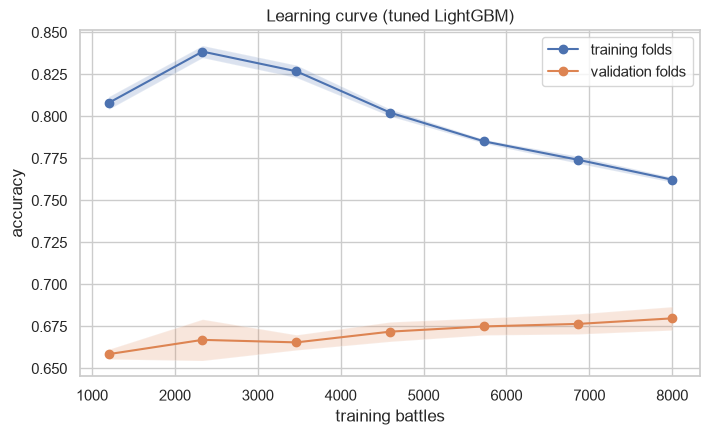

,train_size,train,validation
0,1200,0.8080,0.6585
1,2333,0.8386,0.6670
2,3466,0.8268,0.6655
3,4600,0.8022,0.6719
4,5733,0.7851,0.6750
5,6866,0.7742,0.6765
6,8000,0.7623,0.6798


In [23]:
t0 = time.time()
sizes, train_sc, val_sc = learning_curve(
    model, X, y, train_sizes=np.linspace(0.15, 1.0, 7),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), scoring="accuracy", n_jobs=N_JOBS)
print(f"done in {time.time() - t0:.0f}s")

plt.figure(figsize=(8, 4.5))
for sc, label in [(train_sc, "training folds"), (val_sc, "validation folds")]:
    plt.plot(sizes, sc.mean(axis=1), "o-", label=label)
    plt.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=0.2)
plt.xlabel("training battles")
plt.ylabel("accuracy")
plt.title("Learning curve (tuned LightGBM)")
plt.legend()
plt.show()
pd.DataFrame({"train_size": sizes, "train": train_sc.mean(axis=1), "validation": val_sc.mean(axis=1)}).round(4)

## 7. A look at single battles

The most confident errors, turn by turn: active Pokémon, HP, status and move of each side.

In [24]:
def show_battle(battle_id):
    b = timeline[timeline["battle_id"] == battle_id]
    wide = b.pivot(index="turn", columns="side", values=["name", "hp_pct", "status", "move"])
    wide.columns = [f"{side}_{field}" for field, side in wide.columns]
    order = [f"{s}_{f}" for s in ("p1", "p2") for f in ("name", "hp_pct", "status", "move")]
    r = df.loc[battle_id]
    print(f"battle {battle_id} | P1 won: {int(r['y'])} | predicted p = {r['p']:.3f}")
    display(wide[order].fillna(""))

worst = df[~df["correct"]].sort_values("conf", ascending=False).head(3)
for bid in worst.index:
    show_battle(bid)

battle 5086 | P1 won: 1 | predicted p = 0.067


,p1_name,p1_hp_pct,p1_status,p1_move,p2_name,p2_hp_pct,p2_status,p2_move
turn,,,,,,,,
1,forretress,0.0,fnt,,blissey,1.0,,flamethrower
2,marowak,1.0,,,blissey,1.0,,flamethrower
3,zapdos,1.0,tox,,blissey,1.0,,toxic
4,zapdos,1.0,tox,lightscreen,blissey,1.0,,toxic
5,zapdos,0.94,tox,reflect,blissey,1.0,,toxic
6,gengar,1.0,,,blissey,1.0,,toxic
7,gengar,1.0,,hypnosis,tyranitar,1.0,,
8,gengar,1.0,,hypnosis,gengar,1.0,slp,
9,marowak,1.0,,,tyranitar,1.0,,


battle 7989 | P1 won: 1 | predicted p = 0.068


,p1_name,p1_hp_pct,p1_status,p1_move,p2_name,p2_hp_pct,p2_status,p2_move
turn,,,,,,,,
1,forretress,0.592068,,toxic,marowak,1.0,tox,earthquake
2,forretress,0.654391,,spikes,marowak,0.93808,tox,swordsdance
3,forretress,0.0,fnt,spikes,marowak,0.93808,tox,earthquake
4,starmie,1.0,,,marowak,0.93808,tox,earthquake
5,starmie,1.0,,hydropump,starmie,0.93808,,
6,starmie,1.0,,thunderbolt,starmie,0.452012,,rapidspin
7,starmie,1.0,,thunderbolt,dragonite,0.85974,,
8,starmie,1.0,par,icebeam,dragonite,0.088312,,thunderwave
9,starmie,1.0,par,thunderbolt,dragonite,0.877922,slp,rest


battle 4487 | P1 won: 1 | predicted p = 0.079


,p1_name,p1_hp_pct,p1_status,p1_move,p2_name,p2_hp_pct,p2_status,p2_move
turn,,,,,,,,
1,snorlax,0.16,,curse,hitmontop,1.0,,highjumpkick
2,snorlax,0.0,fnt,selfdestruct,onix,0.06,,
3,exeggutor,1.0,,,onix,0.06,,
4,exeggutor,0.23,,,blastoise,1.0,,
5,exeggutor,0.0,fnt,,blastoise,1.0,,hyperbeam
6,raikou,1.0,,,blastoise,1.0,,hyperbeam
7,raikou,1.0,,thunderbolt,blastoise,0.39,,hyperbeam
8,raikou,1.0,,thunderbolt,quagsire,1.0,,
9,raikou,0.38,,roar,hitmontop,1.0,,highjumpkick


## 8. Summary

This analysis is experiment 05 in `EXPERIMENTS.md`.

**OOF accuracy**: 0.6798 / 0.6784 / 0.6755 (seeds 42 / 7 / 123), 0.6795 averaging the three, consistent with
experiment 04.

1. **The model is well calibrated** (section 2): the calibration curve lies on the diagonal, and the mean
   predicted probability matches the real P1 win rate in every bin of `diff_hp_total`, `diff_lost_est`, `p1_ko`
   and the HP trend (section 3). Only at the extremes (`diff_lost_est ≥ 4`, `p1_ko = 6`) the model is slightly
   less confident than it could be, but those battles are already predicted correctly.
2. **Errors are concentrated in the open battles.** Battles with p between 0.35 and 0.65 are 46% of the
   total, have an accuracy of 0.53-0.62 and contain **62% of the errors**. Confident predictions (p ≤ 0.2 or
   ≥ 0.8) are 19% of the battles, with accuracy 0.85-0.95, and contain 8% of the errors.
3. **Slices** (section 3): the model is worse where the battle is balanced (|`diff_hp_total`| < 0.5: 0.62;
   same `lost_est` on both sides: 0.62; no KO at all: 0.65) and better where it is already decided (≥ 1.5 HP
   difference: 0.80). Boosts, sleep, Explosion, hazards, Substitute, unseen P2 Pokémon and under-levelled
   battles are all within ±1.5 points of the average: none of them is a weak spot.
4. **The most confident errors** (section 7) are comebacks from a lost position: in two of them P1 had 5
   Pokémon fainted against almost none for P2. One battle is won by P1 with 6 recorded KOs, which suggests a
   forfeit or label noise. No feature of the first 30 turns can predict them.
5. **No signal left in the residuals** (section 5):
   - species: 2 of 80 species-column pairs have |z| > 3, against about 0.2 expected by chance; with 57 and 151
     battles this is not usable. Consistent with experiment 03 (target encoding: no gain);
   - candidate features: species-weighted HP is redundant (r = 0.99 with existing features); sleeping alive
     Pokémon, lead changes, last KO and distinct moves revealed have |r| ≤ 0.018 with the residual;
   - the correlations of existing HP features with the residual are a Spearman artefact (see the caveat in
     5.1), not missing information.
6. **The learning curve is still rising** (section 6): validation accuracy goes from 0.659 with 1,200 battles
   to 0.680 with 8,000, about +0.3 points per 1,000 battles at the end, with a large train / validation gap
   (0.76 vs 0.68). More data would help, but external data are forbidden. It partly explains why the final
   models, trained on all 10,000 battles, score a bit higher on the public leaderboard (~0.69).
7. Section 4 (confident errors within each predicted class) was rewritten after the first run and must be
   re-run before its results are used.

**Decision.** With the information of the first 30 turns we are close to the limit: the model is calibrated,
errors are in genuinely open battles, and neither species nor the five candidate features add information.
One last feature experiment (06) is worth trying: type and speed matchups between **all** of P1's remaining
Pokémon and the P2 Pokémon revealed so far (not only the two active ones). It is kept only if the repeated CV
gains more than ~0.5 points; otherwise the features are frozen.